# Evaluating Machine Learning Models for Customer Purchase Prediction

**Research question:** Can demographic, product and transaction characteristics predict purchase amount in this customer-shopping dataset?

**Built from the original BSc data science assignemnt.** This updated version preserves the earlier interests in age, category, seasonality and regression while fixing evaluation and encoding issues. It is an observational, cross-sectional dataset; results are associations/predictions, **not causal effects** or time-series forecasts.

**Reproducibility:** Place `shopping_trends.csv` beside this notebook and run all cells. All random splits use seed 42.

## 1. Load and audit original data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("shopping_trends.csv")
df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
print("Missing cells:", int(df.isna().sum().sum()))
print("Duplicate customer IDs:", int(df["Customer ID"].duplicated().sum()))
display(df.head())
display(df.dtypes.to_frame("dtype"))

Rows, columns: (3900, 19)
Missing cells: 0
Duplicate customer IDs: 0


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually


,dtype
Customer ID,int64
Age,int64
Gender,object
Item Purchased,object
Category,object
Purchase Amount (USD),int64
Location,object
Size,object
Color,object
Season,object


## 2. Exploratory Data Analysis (EDA)

These analyses update the original **Age vs Purchase Amount**, **Category vs Purchase Amount**, and **Seasonality** notebooks. Group comparisons are descriptive: no causal interpretation is warranted.

count    3900.00
mean       59.76
std        23.69
min        20.00
25%        39.00
50%        60.00
75%        81.00
max       100.00
Name: Purchase Amount (USD), dtype: float64


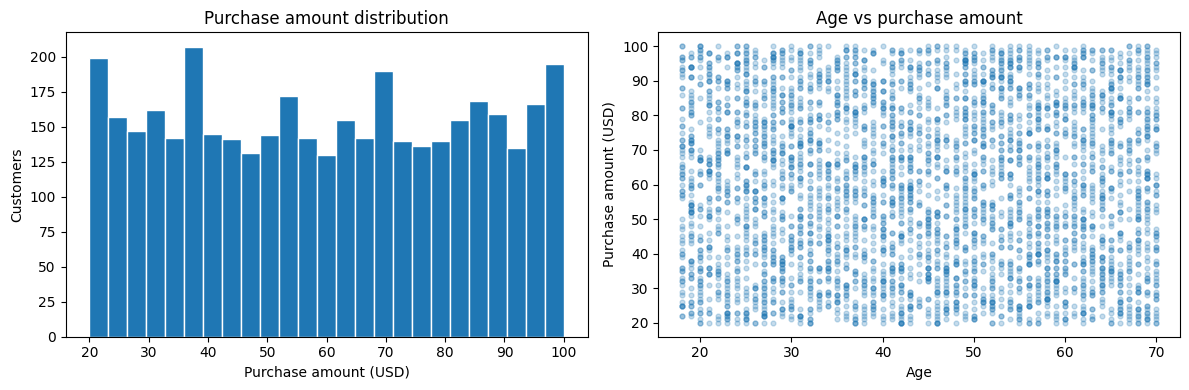

In [ ]:

target = "Purchase Amount (USD)"
print(df[target].describe().round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df[target], bins=25, edgecolor="white")
axes[0].set(title="Purchase amount distribution", xlabel="Purchase amount (USD)", ylabel="Customers")
axes[1].scatter(df["Age"], df[target], alpha=0.25, s=12)
axes[1].set(title="Age vs purchase amount", xlabel="Age", ylabel="Purchase amount (USD)")
plt.tight_layout(); plt.show()

,count,mean,median
Category,,,
Accessories,1240,59.84,60.0
Clothing,1737,60.03,60.0
Footwear,599,60.26,60.0
Outerwear,324,57.17,54.5


Season,Fall,Spring,Summer,Winter
Category,,,,
Accessories,61.34,56.50,60.99,60.37
Clothing,61.41,61.00,56.56,60.88
Footwear,63.71,58.62,58.71,60.57
Outerwear,59.76,54.63,57.04,57.02


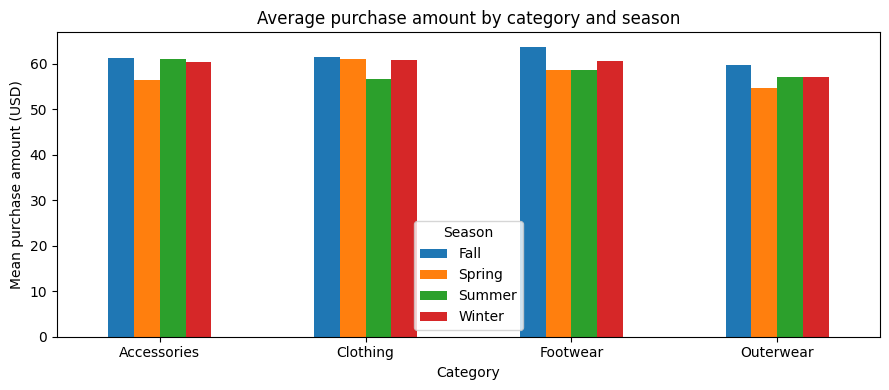

In [ ]:
# calcualte the count, mean, and median

category_summary = df.groupby("Category")[target].agg(["count", "mean", "median"]).round(2)
season_category = df.pivot_table(index="Category", columns="Season", values=target, aggfunc="mean")
display(category_summary)
display(season_category.round(2))
fig, ax = plt.subplots(figsize=(9, 4))
season_category.plot(kind="bar", ax=ax)
ax.set(title="Average purchase amount by category and season", ylabel="Mean purchase amount (USD)", xlabel="Category")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 3. Prediction design

I predict **purchase amount**, not review rating. `Customer ID` is excluded because it is an identifier. `Review Rating` is also excluded to avoid relying on a potentially post-purchase outcome. Categorical transformations are **fit on training data only** through a scikit-learn pipeline. No target encoding or scaling of the target is applied.

A random holdout split estimates performance for similar observations from this dataset; it does **not** establish performance for future periods or other populations.

In [4]:
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

excluded = ["Customer ID", "Review Rating", target]
X = df.drop(columns=excluded)
y = df[target]
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print("Numeric:", numeric_cols)
print("Categorical:", category_cols)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
category_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocess = ColumnTransformer([("num", numeric_pipe, numeric_cols), ("cat", category_pipe, category_cols)])
models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": Pipeline([("prep", preprocess), ("model", LinearRegression())]),
    "Random Forest": Pipeline([("prep", preprocess), ("model", RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1))]),
}

Numeric: ['Age', 'Previous Purchases']
Categorical: ['Gender', 'Item Purchased', 'Category', 'Location', 'Size', 'Color', 'Season', 'Subscription Status', 'Payment Method', 'Shipping Type', 'Discount Applied', 'Promo Code Used', 'Preferred Payment Method', 'Frequency of Purchases']


## 4. Train on training data; evaluate on untouched test data

In [ ]:
rows = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({"Model": name, "MAE": mean_absolute_error(y_test, pred),
                 "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                 "R²": r2_score(y_test, pred)})
results = pd.DataFrame(rows).set_index("Model").sort_values("MAE")
display(results.round(3))

,MAE,RMSE,R²
Model,,,
Baseline (mean),20.756,23.731,-0.006
Linear Regression,20.945,24.049,-0.034
Random Forest,21.027,24.089,-0.037


Note: negative R² means worse than predicting the TEST-set mean.


## 5. Cross-validation on the training set only

In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
                            n_jobs=1)
    cv_rows.append({"Model": name, "CV MAE mean": -scores["test_mae"].mean(),
                    "CV MAE SD": scores["test_mae"].std(), "CV R² mean": scores["test_r2"].mean()})
cv_results = pd.DataFrame(cv_rows).set_index("Model")
display(cv_results.round(3))

,CV MAE mean,CV MAE SD,CV R² mean
Model,,,
Baseline (mean),20.567,0.214,-0.001
Linear Regression,20.725,0.334,-0.049
Random Forest,20.718,0.237,-0.033


## 6. Diagnostic plots and transparent interpretation

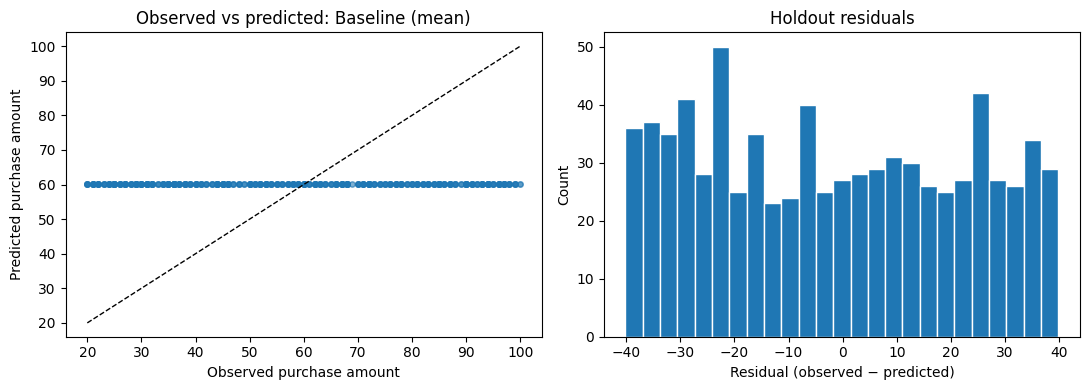

Best holdout MAE model: Baseline (mean)
Interpretation: Compare against the mean baseline; if no model improves, report that result rather than claiming predictive success.


In [7]:
best_name = results.index[0]
best_pred = predictions[best_name]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, best_pred, alpha=0.35, s=15)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "k--", linewidth=1)
axes[0].set(xlabel="Observed purchase amount", ylabel="Predicted purchase amount", title=f"Observed vs predicted: {best_name}")
axes[1].hist(y_test.to_numpy() - best_pred, bins=25, edgecolor="white")
axes[1].set(xlabel="Residual (observed − predicted)", ylabel="Count", title="Holdout residuals")
plt.tight_layout(); plt.show()
print("Best holdout MAE model:", best_name)
print("Interpretation: Compare against the mean baseline; if no model improves, report that result rather than claiming predictive success.")

## 7. Research limitations and next steps

1. **Observational data:** Relationships between variables and spending are associations, not causal effects.
2. **Sampling and provenance:** The source dataset's representativeness and data-collection design are not established here; avoid generalizing to all consumers.
3. **Season is categorical:** There is no transaction date or temporal sequence, so this is **not** a forecasting study.
4. **Possible post-purchase information:** Variables such as shipping, discount or payment method may be known only during/after checkout; results are conditional on information availability. Excluding review rating is a precaution.
5. **Weak prediction is informative:** Negative or near-zero R² is a valid research finding, not a reason to hide results.
6. **Further research:** Try pre-purchase-only features, repeated cross-validation, and a separate external dataset; report uncertainty and compare against baselines.
